# 2. How do the labels become searchable?

A drug label can be many pages long. We split its text into smaller passages so a search can return the useful part.

This notebook describes the **current 60-drug collection** and its saved search index. It uses local files and makes no API calls.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.utils.config import read_json

from src.ingestion.data_loader import load_snapshot

index_path = ROOT / read_json(ROOT / "results/search_latest.json")["run_path"]
index = read_json(index_path)
snapshot = load_snapshot(index["snapshot_id"])
coverage = index["coverage"]

## How much text is in a label?

Labels are organised into sections such as warnings, dosage and ingredients. The table shows the longest labels in our sample.

A **token** is a small piece of text used by the model. It can be a word or part of a word, so token counts are not word counts.

In [2]:
from src.preprocessing.chunking import token_count

labels = [document for document in snapshot["documents"] if document["kind"] == "fda_full"]
label_rows = []
section_rows = []
for label in labels:
    name = " / ".join(label["metadata"]["generic_name"]) or "Name field missing"
    label_rows.append(
        {
            "Label name": name,
            "Sections": len(label["sections"]),
            "Tokens": sum(token_count(text) for text in label["sections"].values()),
        }
    )
    for section, text in label["sections"].items():
        section_rows.append({"Section": section.replace("_", " ").title(), "Tokens": token_count(text)})
display(pd.DataFrame(label_rows).nlargest(8, "Tokens").reset_index(drop=True))

,Label name,Sections,Tokens
0,LAMOTRIGINE,17,34311
1,OLANZAPINE,17,31025
2,Name field missing,17,30768
3,QUETIAPINE FUMARATE,17,30660
4,QUETIAPINE FUMARATE,17,30652
5,TOPIRAMATE,16,30244
6,TRAMADOL HYDROCHLORIDE,17,28781
7,"VENLAFAXINE HYDROCHLORIDE, EXTENDED RELEASE",17,27913


## Which sections tend to be long?

Each bar shows the middle, or median, length of one section type. We show the ten longest section types by that measure. Longer sections may need several passages.

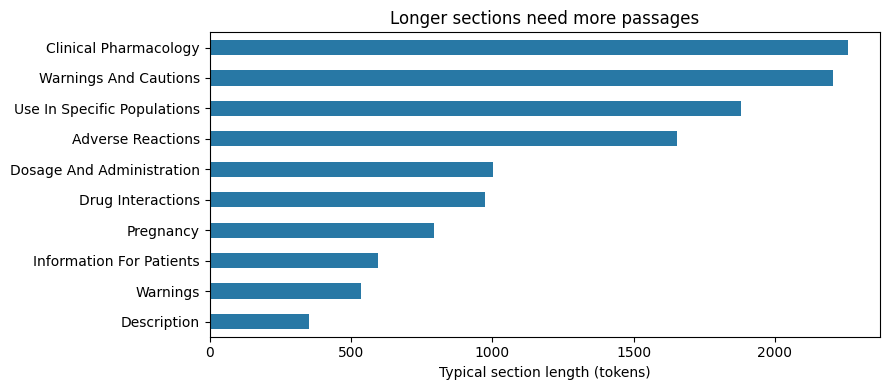

In [3]:
import matplotlib.pyplot as plt

sections = pd.DataFrame(section_rows)
typical_lengths = sections.groupby("Section")["Tokens"].median().nlargest(10).sort_values()
ax = typical_lengths.plot.barh(figsize=(9, 4), color="#2878a5")
ax.set(xlabel="Typical section length (tokens)", ylabel="", title="Longer sections need more passages")
plt.tight_layout()
plt.show()

## How do we split the text?

Passages stay inside their original label section. We aim to split at natural text boundaries and limit each passage to 256 tokens. Neighbouring passages share a small amount of text, up to about 32 tokens, to help keep nearby context together.

We keep the original words, drug name, section, date and source link. The table describes the passages already stored in the active index.

In [4]:
chunks = pd.DataFrame(read_json(index_path.parent / "chunks.json"))
index_summary = {
    "Drug names covered": coverage["covered_names"],
    "Full FDA labels": chunks["set_id"].nunique(),
    "Searchable passages": len(chunks),
    "Typical passage length (tokens)": int(chunks["token_count"].median()),
    "Largest passage (tokens)": int(chunks["token_count"].max()),
}
display(pd.Series(index_summary).rename("Count").to_frame())

,Count
Drug names covered,60
Full FDA labels,118
Searchable passages,8601
Typical passage length (tokens),242
Largest passage (tokens),256


## Try your own question

Enter a drug name or question in `question` below and run the cell. This example uses **BM25**, which ranks passages using matching words and how distinctive those words are. It works without an API call.

The results are excerpts from labels, not a generated answer. The source link lets you inspect the full label; a live FDA link may show a newer version than the saved text.

Matching words can also return unrelated passages. Check the drug name, section and surrounding text before using a result.

In [5]:
from src.retrieval.search import SearchSession

question = "apixaban"
session = SearchSession(method="bm25")
response = session.search(question, k=2)
for result in response["results"]:
    display(Markdown(f"**{result['rank']}. {result['identity']}** — {result['section'].replace('_', ' ')}"))
    print(result["text"])
    print("Source:", result["authority_url"])

**1. apixaban | APIXABAN** — spl product data elements

apixaban apixaban APIXABAN APIXABAN ANHYDROUS LACTOSE CELLULOSE, MICROCRYSTALLINE CROSCARMELLOSE SODIUM SODIUM LAURYL SULFATE MAGNESIUM STEARATE LACTOSE MONOHYDRATE HYPROMELLOSE, UNSPECIFIED TITANIUM DIOXIDE TRIACETIN FERRIC OXIDE YELLOW C31 apixaban apixaban APIXABAN APIXABAN ANHYDROUS LACTOSE CELLULOSE, MICROCRYSTALLINE CROSCARMELLOSE SODIUM SODIUM LAURYL SULFATE MAGNESIUM STEARATE LACTOSE MONOHYDRATE HYPROMELLOSE, UNSPECIFIED TITANIUM DIOXIDE TRIACETIN FERRIC OXIDE RED C32
Source: https://api.fda.gov/drug/label.json?search=set_id:%22095a08ac-cf0e-497e-a682-ddef38d6b29c%22


**2. apixaban | APIXABAN** — dosage and administration

 apixaban: Warfarin should be discontinued and apixaban started when the international normalized ratio (INR) is below 2.0. Switching from apixaban to warfarin: apixaban affects INR, so that initial INR measurements during the transition to warfarin may not be useful for determining the appropriate dose of warfarin. One approach is to discontinue apixaban and begin both a parenteral anticoagulant and warfarin at the time the next dose of apixaban would have been taken, discontinuing the parenteral anticoagulant when INR reaches an acceptable range. Switching from apixaban to anticoagulants other than warfarin (oral or parenteral): Discontinue apixaban and begin taking the new anticoagulant other than warfarin at the usual time of the next dose of apixaban. 
Source: https://api.fda.gov/drug/label.json?search=set_id:%22095a08ac-cf0e-497e-a682-ddef38d6b29c%22


## What did we learn?

Labels vary in length, so one label may produce many passages. Splitting makes it easier to find a relevant section, but a short passage can miss context. Always inspect the surrounding label when a detail matters.

This notebook shows that the collection is searchable. **Notebook 3 compares search methods using the earlier, smaller test collection.**